# Running RolmOCR on Vast

[RolmOCR](https://huggingface.co/reducto/RolmOCR) from Reducto is a powerful, open-source document OCR solution that delivers superior performance while requiring fewer resources than comparable models. Built on Qwen2.5-VL-7B, this model excels at parsing complex documents including PDFs, invoices, and forms without requiring metadata extraction. Because it is open source, companies can build on top of this model for their own proprietary pipelines while not sending data to other providers or model hosting services.

Vast.ai offers a GPU marketplace where you can rent compute power at lower costs than major cloud providers, with the flexibility to select specific hardware configurations optimized for specific models, while keeping all of your company's data private.

This notebook demonstrates how to extract structured pricing data from invoice images using `reducto/RolmOCR`.

## Deploy `reducto/RolmOCR` on Vast

### Install Vast

First, we will install and set up the Vast API.

You can get your API key on the [Account Page](https://cloud.vast.ai/account/) in the Vast Console and set it below in `VAST_API_KEY`

In [ ]:
%%bash
# For CPU-only operations, ex running the benchmark
pip install olmocr[gpu] olmocr[bench]

# For actually converting the files with your own GPU
# pip install   # --extra-index-url https://download.pytorch.org/whl/cu128

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.5/48.5 kB 2.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.0/42.0 kB 2.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 106.5/106.5 kB 3.3 MB/s eta 0:00:00
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 438.2/438.2 MB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 180.0/180.0 kB 11.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 111.0/111.0 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.4/45.4 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 44.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 41.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
cudf-cu12 25.6.0 requires pyarrow<20.0.0a0,>=14.0.0; platform_machine == "x86_64", but you have pyarrow 21.0.0 which is incompatible.


In [ ]:
%%bash
pip install --upgrade openai datasets pydantic
# pip install vastai==0.2.6

In [ ]:
from PIL import Image
import base64
from datasets import load_dataset
import io
import json
import matplotlib.pyplot as plt
from openai import OpenAI
from pydantic import BaseModel
from rich import print

In [ ]:
def get_results(subset):
  invoices = []
  ground_truth = []
  for sample in subset:
      # Display the image
      plt.figure(figsize=(10, 14))
      plt.imshow(sample['image'])
      plt.axis('off')
      plt.show()

      # Process with OCR
      img_base64 = encode_pil_image(sample['image'])
      result = ocr_page_with_rolm(img_base64)
      result_dict = json.loads(result)
      invoices.append(result_dict)

      ground_truth_i = json.loads(sample["ground_truth"])
      ground_truth_dict = {
          "invoice_number":ground_truth_i["gt_parse"]["header"]["invoice_no"],
          "invoice_amount":ground_truth_i["gt_parse"]["summary"]["total_gross_worth"]
      }
      ground_truth.append(ground_truth_dict)

      print("Ground Truth")
      print(ground_truth_dict)

      print("Extracted Info")
      print(result_dict)

In [ ]:
def ocr_page_with_rolm(img_base64):
    response = client.chat.completions.create(
        model=model,
        messages=[
            {
                "role": "user",
                "content": [
                    {
                        "type": "image_url",
                        "image_url": {"url": f"data:image/png;base64,{img_base64}"},
                    },
                    {
                        "type": "text",
                        "text": "Return the invoice number and total amount for each invoice as a json: {invoice_number : str, invoice_amount: str}",
                    },
                ],
            }
        ],
        extra_body={"guided_json": json_schema},
        temperature=0.2,
        max_tokens=500
    )
    return response.choices[0].message.content

In [ ]:
def encode_pil_image(pil_image):
    # Resize image to a smaller size while maintaining aspect ratio
    max_size = 1024  # Maximum dimension
    ratio = min(max_size / pil_image.width, max_size / pil_image.height)
    new_size = (int(pil_image.width * ratio), int(pil_image.height * ratio))
    resized_image = pil_image.resize(new_size, Image.Resampling.LANCZOS)

    # Convert PIL Image to bytes
    img_byte_arr = io.BytesIO()
    resized_image.save(img_byte_arr, format='JPEG', quality=85)  # Reduced quality for smaller size
    img_byte_arr = img_byte_arr.getvalue()
    return base64.b64encode(img_byte_arr).decode("utf-8")

### Enforcing Structured Data Extraction

We'll define an `Invoice` schema with Pydantic to ensure our model returns precisely formatted data.

In [ ]:
class Invoice(BaseModel):
    invoice_number: str
    invoice_amount: str

In [ ]:
json_schema = Invoice.model_json_schema()
print(json_schema)

{
    'properties': {
        'invoice_number': {'title': 'Invoice Number', 'type': 'string'},
        'invoice_amount': {'title': 'Invoice Amount', 'type': 'string'}
    },
    'required': ['invoice_number', 'invoice_amount'],
    'title': 'Invoice',
    'type': 'object'
}

In [ ]:
IP_ADDRESS = "172.0.0.1"
PORT = ""
base_url = f"http://{IP_ADDRESS}:{PORT}/v1"
model = "reducto/RolmOCR"

HF_TOKEN=""
VAST_API_KEY="" #Your key here
INSTANCE_ID= #insert instance ID

In [ ]:
%%bash

# vastai set api-key $VAST_API_KEY

## Search for an Instance

Next, we'll search for an instance to host our model. While `reducto/RolmOCR` requires at least 16GB VRAM, we'll select an instance with 60GB VRAM to accommodate larger documents and enable a wider context window.

In [ ]:
%%bash
vastai search offers "compute_cap >= 750 \
geolocation=US \
gpu_ram >= 60 \
num_gpus = 1 \
static_ip = true \
direct_port_count >= 1 \
verified = true \
disk_space >= 80 \
rentable = true"

### Deploy our Instance

Finally, we will use the instance ID from our search to deploy our model to our instance.

Note: we set `VLLM_USE_V1=1` to use the v1 engine for vLLM, which `reducto/RolmOCR` requires.

In [ ]:
%%bash
vastai create instance $INSTANCE_ID --image vllm/vllm-openai:latest --env '-p 8000:8000 -e VLLM_USE_V1=1' --disk 80 --args --model reducto/RolmOCR

## Using the OpenAI API to Call `reducto/RolmOCR`


### Download dependencies
First, we will install our dependencies.


### Download Sample Invoice Data

We will use `datasets` to get a subset of the invoice data from the `katanaml-org/invoices-donut-data-v1` dataset on Hugging Face, which contains 500 annotated invoice images with structured metadata for training document extraction models.

In [ ]:
# Stream the dataset
streamed_dataset = load_dataset("katanaml-org/invoices-donut-data-v1", split="train", streaming=True)
print(type(streamed_dataset))

<class 'datasets.iterable_dataset.IterableDataset'>

In [ ]:


# Take the first 3 samples
subset = list(streamed_dataset.take(3))

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

We will then create an `encode_pil_image` function to convert the images from our dataset to a base64 encoded image to be passed into the OpenAI API.

In [ ]:
print(subset[0])

{
    'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=2481x3508 at 0x7811A28E88F0>,
    'ground_truth': '{"gt_parse": {"header": {"invoice_no": "40378170", "invoice_date": "10/15/2012", "seller": 
"Patel, Thompson and Montgomery 356 Kyle Vista New James, MA 46228", "client": "Jackson, Odonnell and Jackson 267 
John Track Suite 841 Jenniferville, PA 98601", "seller_tax_id": "958-74-3511", "client_tax_id": "998-87-7723", 
"iban": "GB77WRBQ31965128414006"}, "items": [{"item_desc": "Leed\'s Wine Companion Bottle Corkscrew Opener Gift Box
Set with Foil Cutter", "item_qty": "1,00", "item_net_price": "7,50", "item_net_worth": "7,50", "item_vat": "10%", 
"item_gross_worth": "8,25"}], "summary": {"total_net_worth": "$7,50", "total_vat": "$0,75", "total_gross_worth": 
"$8,25"}}}'
}

## Configuring the API Client

Next, we'll create our `ocr_page_with_rolm` function that interfaces with the RolmOCR endpoint.

We'll also add our `VAST_IP_ADDRESS` and `VAST_PORT` for our running instance. We'll find these in the [Instances tab](https://cloud.vast.ai/instances/) of our Vast AI Console.

In [ ]:
client = OpenAI(api_key="", base_url=base_url)

Next, we will iterate over our subset to extract `invoice_number` and `invoice_amount`. We will display the original invoice and compare our json output to the ground truth data.

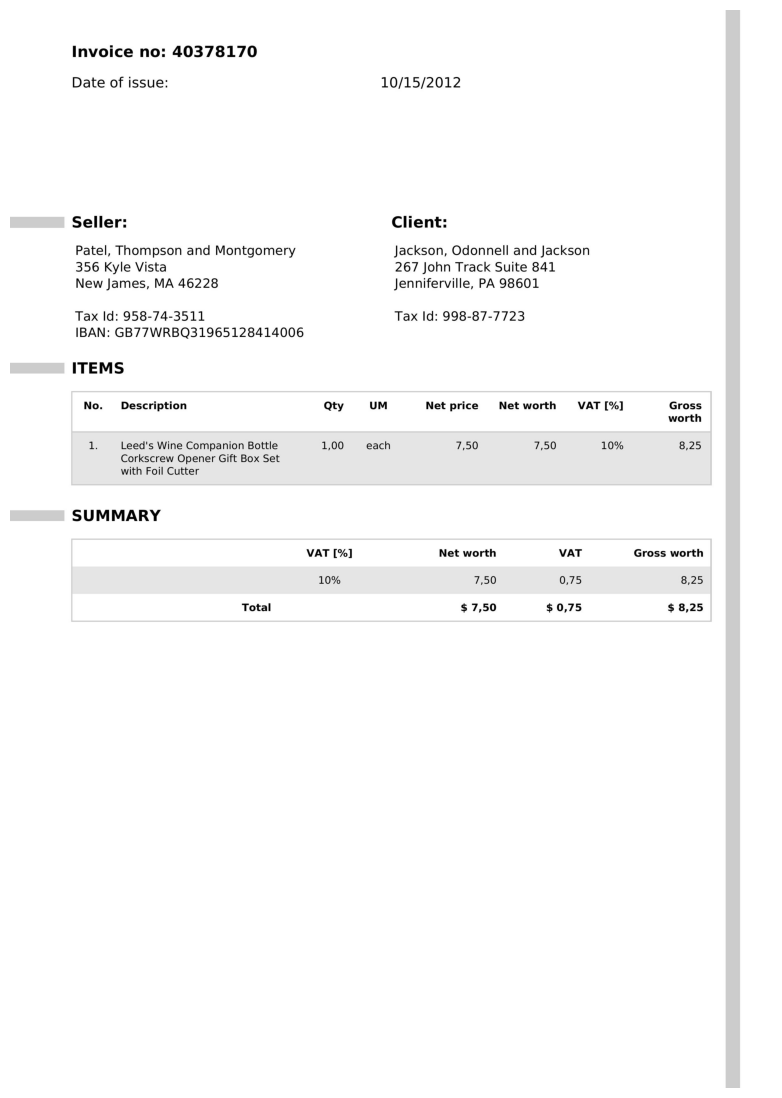

ImportError: cannot import name 'VideoSize' from 'openai.types' (/usr/local/lib/python3.12/dist-packages/openai/types/__init__.py)

In [ ]:
get_results(subset)

### Output

![](./img/output_1.png)

```
Ground Truth
{'invoice_number': '40378170', 'invoice_amount': '$8,25'}
Extracted Info
{'invoice_number': '40378170', 'invoice_amount': '$8.25'}
```


![](./img/output_2.png)


```
Ground Truth
{'invoice_number': '61356291', 'invoice_amount': '$ 212,09'}
Extracted Info
{'invoice_number': '61356291', 'invoice_amount': '$212.09'}
```


![](./img/output_3.png)

```
Ground Truth
{'invoice_number': '49565075', 'invoice_amount': '$96,73'}
Extracted Info
{'invoice_number': '49565075', 'invoice_amount': '$96,73'}
```

We see that the output from `reducto/RolmOCR` matches the expected output from the ground truth associated with each invoice.

## Conclusion

In this notebook, we've demonstrated how to deploy and use RolmOCR on Vast to extract structured data from invoice images.

RolmOCR proves to be highly accurate at identifying key information like invoice numbers and amounts. The combination of RolmOCR's efficiency with Vast.ai's cost-effective GPU options makes this an excellent solution for document processing workflows at scale.

This approach can be extended to extract other types of structured data from various document formats, enabling powerful automation capabilities for businesses of all sizes.

